[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/07_Bayesian_Hyperparameter_Optimisation.ipynb)

# 07. Bayesian hyperparameter optimisation of LightGBM (Optuna TPE)
**Run on:** Laptop B · **Approx. runtime:** ~10-12 min on a 4-core laptop

LightGBM was the best model in the comparison, so it is tuned here.
- **Search:** Optuna's Tree-structured Parzen Estimator (TPE, a Bayesian method), seed 42, 8 random start-up trials, then model-guided.
- **Objective:** maximise the mean **macro F1** over **3-fold GroupKFold by trip** on the training trips (150k-row samples per fold for speed).
- **Afterwards:** the untuned and tuned models are compared with the **same** 5-fold CV and student-test protocol.

**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## Search space

In [3]:
import optuna, time
optuna.logging.set_verbosity(optuna.logging.WARNING)
sys.path.insert(0, os.path.join(ROOT, "scripts"))
from importlib import import_module
space = import_module("03_bayes_opt").space   # the same search space as scripts/03_bayes_opt.py
import inspect; print(inspect.getsource(space).split('if name == "rf"')[0])

def space(trial, name):
    if name == "lightgbm":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
            min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        )
    


In [4]:
N_TRIALS = 20     # increase for a longer search
from pathsnap.experiment import cross_validate

def objective(trial):
    params = space(trial, "lightgbm")
    folds = cross_validate(lambda: make_model("lightgbm", SEED, **params), tr, tr_pts, folds=3,
                           max_rows=150_000, seed=SEED, verbose=False)
    f1 = float(np.mean([f["macro_f1"] for f in folds]))
    print(f"trial {trial.number:2d}: CV macro F1 {f1:.4f}")
    return f1

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8))
t0 = time.time(); study.optimize(objective, n_trials=N_TRIALS); search_s = time.time() - t0
print(f"\nsearch time {search_s:.0f}s | best CV macro F1 {study.best_value:.4f}")
study.best_params

trial  0: CV macro F1 0.8976


trial  1: CV macro F1 0.9252


trial  2: CV macro F1 0.9255


trial  3: CV macro F1 0.9266


trial  4: CV macro F1 0.9274


trial  5: CV macro F1 0.9270


... (11 outputs left out)

trial 17: CV macro F1 0.9272


trial 18: CV macro F1 0.9277


trial 19: CV macro F1 0.9275

search time 977s | best CV macro F1 0.9277


{'n_estimators': 800,
 'learning_rate': 0.010297269320228404,
 'num_leaves': 47,
 'min_child_samples': 13,
 'subsample': 0.7682702370440837,
 'colsample_bytree': 0.8725895231217342,
 'reg_lambda': 3.183496652709331}

## Search record and plots

,number,value,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample
0,0,0.8976,0.5780,0.2537,75,350,118,0.0017,0.5780
1,1,0.9252,0.9162,0.0773,10,700,111,0.0071,0.9850
2,2,0.9255,0.6456,0.0187,58,200,35,0.2802,0.7160
3,3,0.9266,0.5998,0.0270,46,200,41,0.1140,0.8926
4,4,0.9274,0.9744,0.0117,17,500,83,7.2867,0.5325
5,5,0.9270,0.5610,0.0282,101,700,19,0.0957,0.7201
6,6,0.9254,0.7600,0.2204,94,100,30,0.1538,0.6559
7,7,0.9220,0.7989,0.2705,244,200,134,4.8696,0.9474
8,8,0.9253,0.7580,0.0523,10,500,147,0.0238,0.5177
9,9,0.9269,0.8390,0.0255,73,500,122,0.4949,0.8111


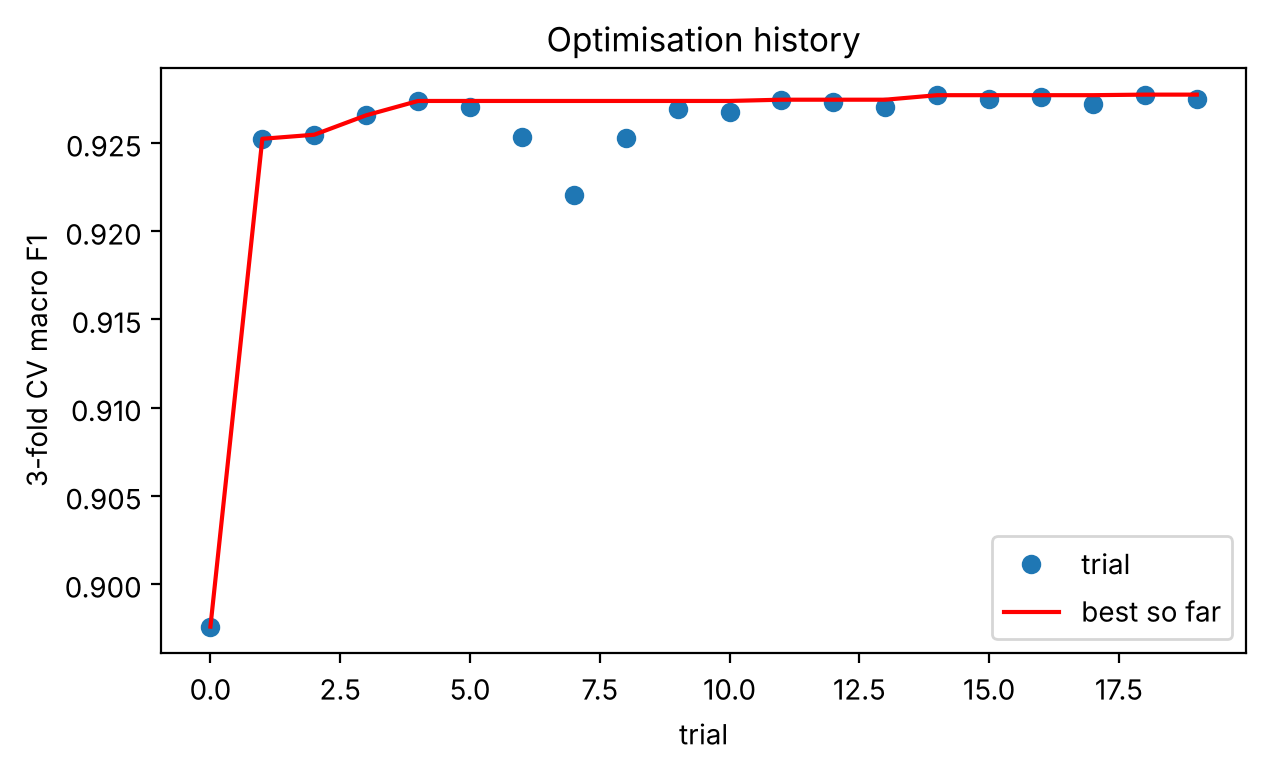

In [5]:
trials = study.trials_dataframe()
os.makedirs("results/02_model_training/notebook_runs", exist_ok=True); trials.to_csv("results/02_model_training/notebook_runs/optuna_trials_lightgbm.csv", index=False)
display(trials[["number", "value"] + [c for c in trials if c.startswith("params_")]].round(4))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(trials.number, trials.value, "o", label="trial"); ax.plot(trials.number, trials.value.cummax(), "r-", label="best so far")
ax.set(xlabel="trial", ylabel="3-fold CV macro F1", title="Optimisation history"); ax.legend(); nb.show()

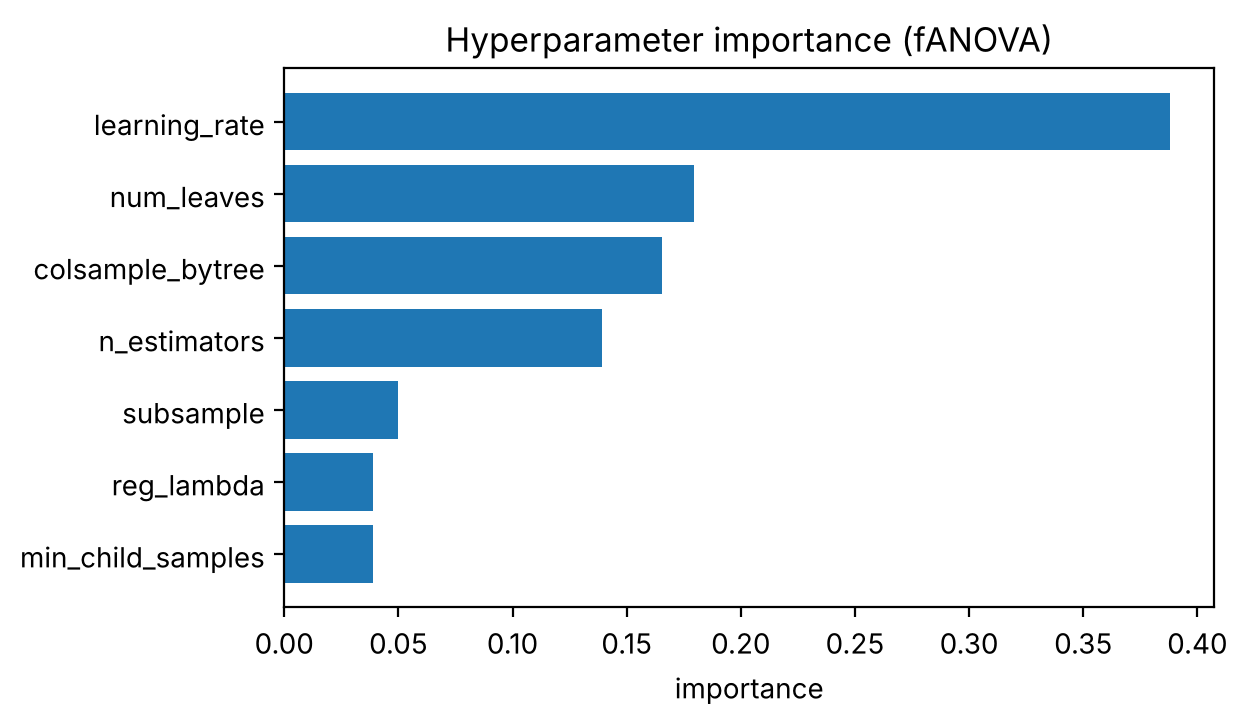

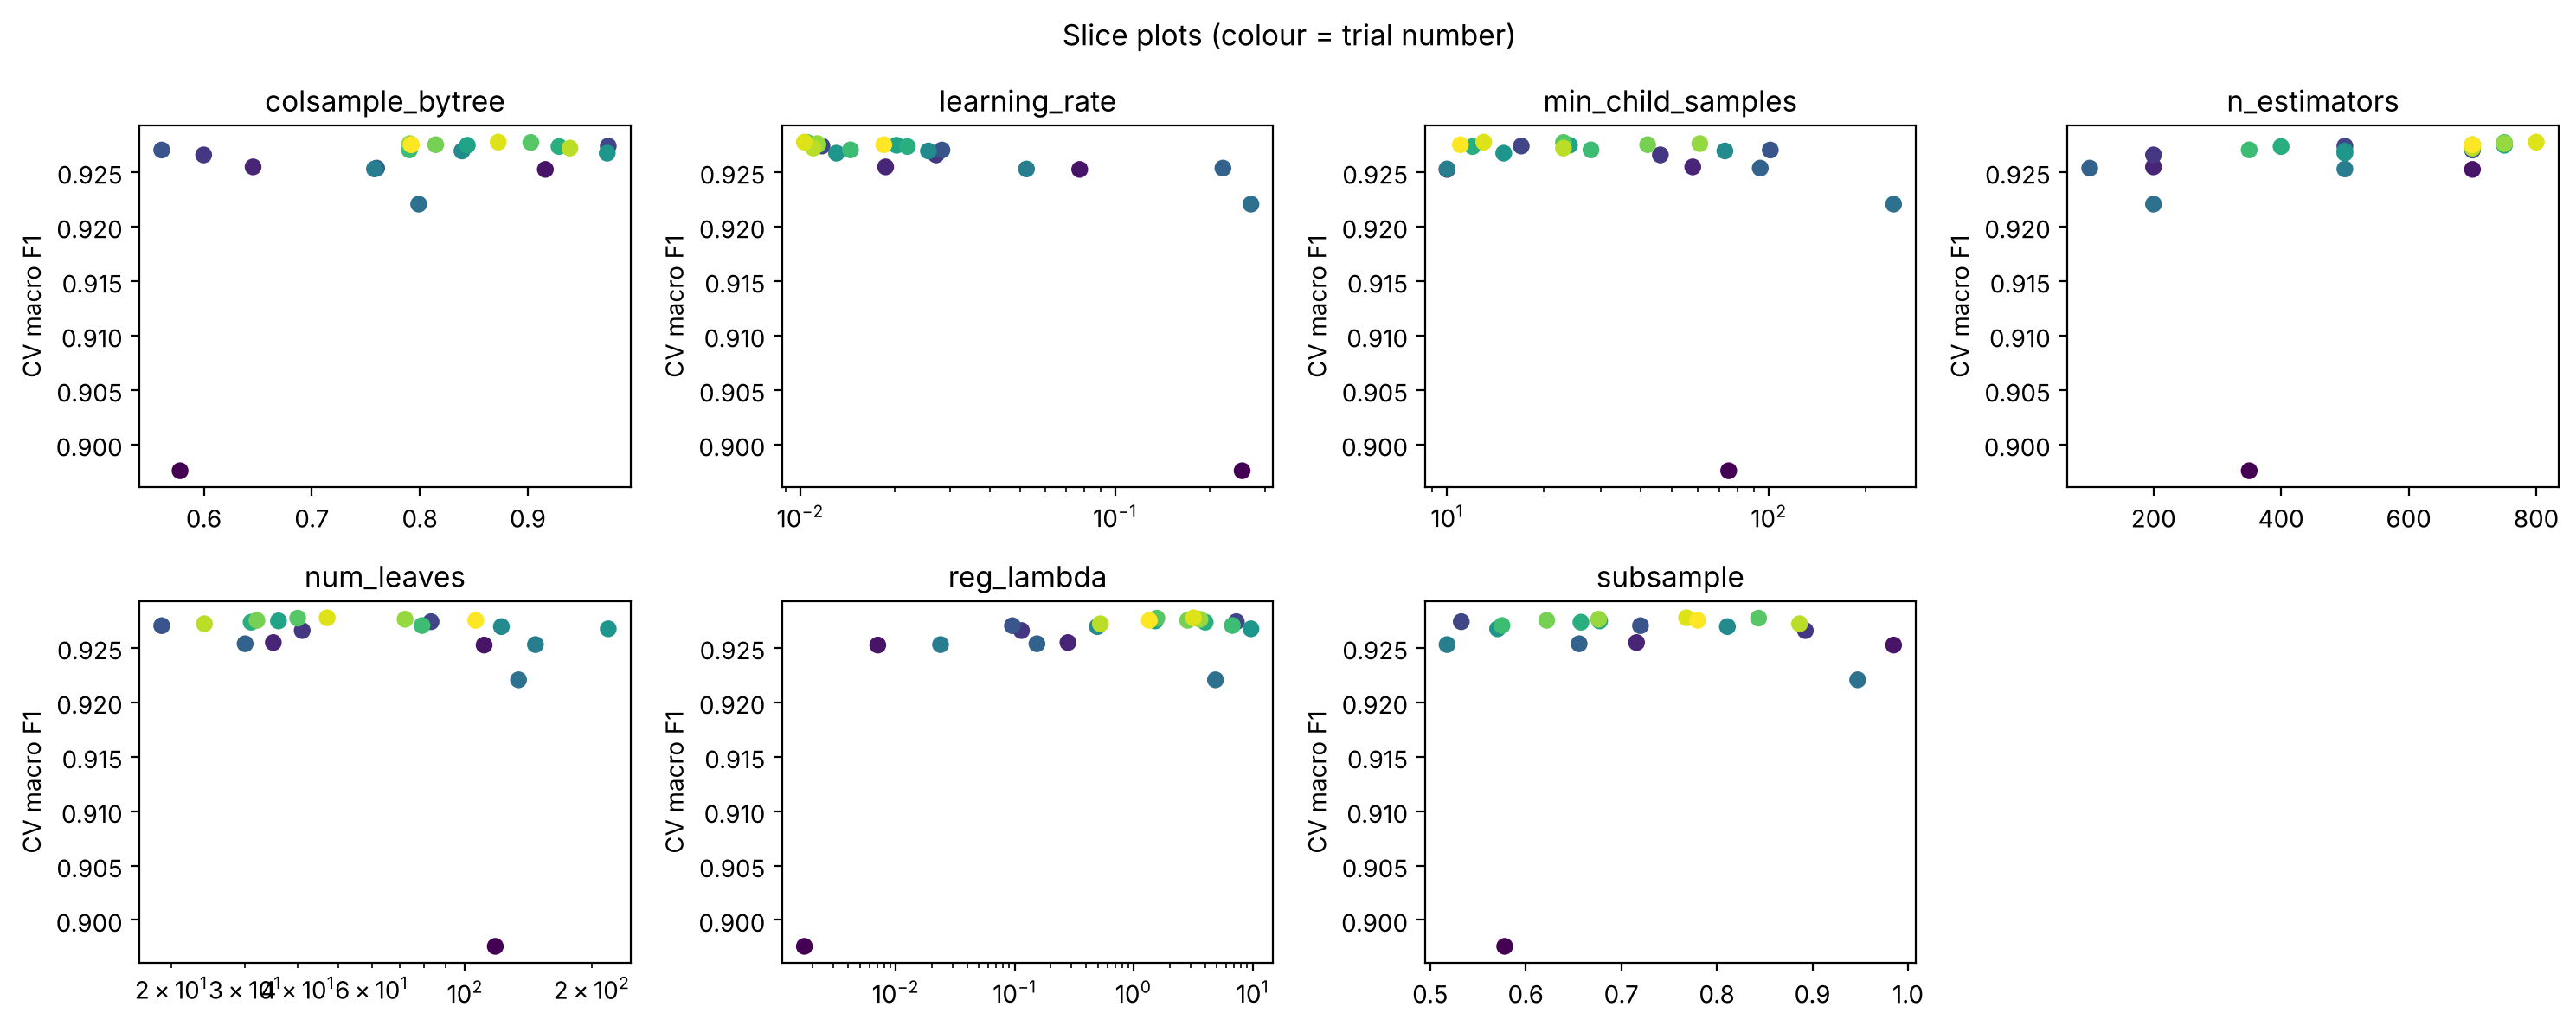

In [6]:
imp = optuna.importance.get_param_importances(study)
plt.figure(figsize=(6, 3.5)); plt.barh(list(imp)[::-1], list(imp.values())[::-1])
plt.title("Hyperparameter importance (fANOVA)"); plt.xlabel("importance"); nb.show()
ps = [c for c in trials if c.startswith("params_")]
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for a, c in zip(axs.ravel(), ps):
    a.scatter(trials[c], trials.value, c=trials.number, cmap="viridis"); a.set(title=c[7:], ylabel="CV macro F1")
    if c[7:] in ("learning_rate", "num_leaves", "min_child_samples", "reg_lambda"): a.set_xscale("log")
axs.ravel()[-1].axis("off"); fig.suptitle("Slice plots (colour = trial number)"); fig.tight_layout(); nb.show()

## Untuned vs tuned (same 5-fold CV and student-test protocol)

In [7]:
res = {}
for label, params in [("untuned", {}), ("tuned", study.best_params)]:
    print(f"=== {label}")
    make = lambda p=params: make_model("lightgbm", SEED, **p)
    cv = nb.run_cv(make, tr, tr_pts)
    model, train_m, test_m, p = nb.fit_and_evaluate(make, tr, tr_pts, te, te_pts)
    res[label] = (cv, train_m, test_m, model)
table = pd.DataFrame({k: {"CV macro F1": v[0].macro_f1.mean(), "CV std": v[0].macro_f1.std(), "test Top-1": v[2]["top1"],
                          "test macro F1": v[2]["macro_f1"], "test log loss": v[2]["log_loss"],
                          "test continuity": v[2]["continuity"], "inference ms/point": v[2]["infer_ms_per_point"],
                          "fit seconds": v[2]["fit_s"]} for k, v in res.items()}).round(4)
table

=== untuned


  fold 0: F1=0.9159 top1=0.8629 ll=0.1367


  fold 1: F1=0.9314 top1=0.8839 ll=0.0939


  fold 2: F1=0.9242 top1=0.8807 ll=0.1340


  fold 3: F1=0.9523 top1=0.9282 ll=0.0734


  fold 4: F1=0.9148 top1=0.8627 ll=0.1210


... (6 outputs left out)

  fold 4: F1=0.9148 top1=0.8617 ll=0.1193


CV time 51s | mean macro F1 0.9278 ± 0.0152


fit 7.1s on 300,108 rows


,untuned,tuned
CV macro F1,0.9277,0.9278
CV std,0.0153,0.0152
test Top-1,0.8871,0.8865
test macro F1,0.9283,0.9288
test log loss,0.1039,0.1039
test continuity,0.9339,0.9327
inference ms/point,0.0347,0.0833
fit seconds,3.4800,7.0533


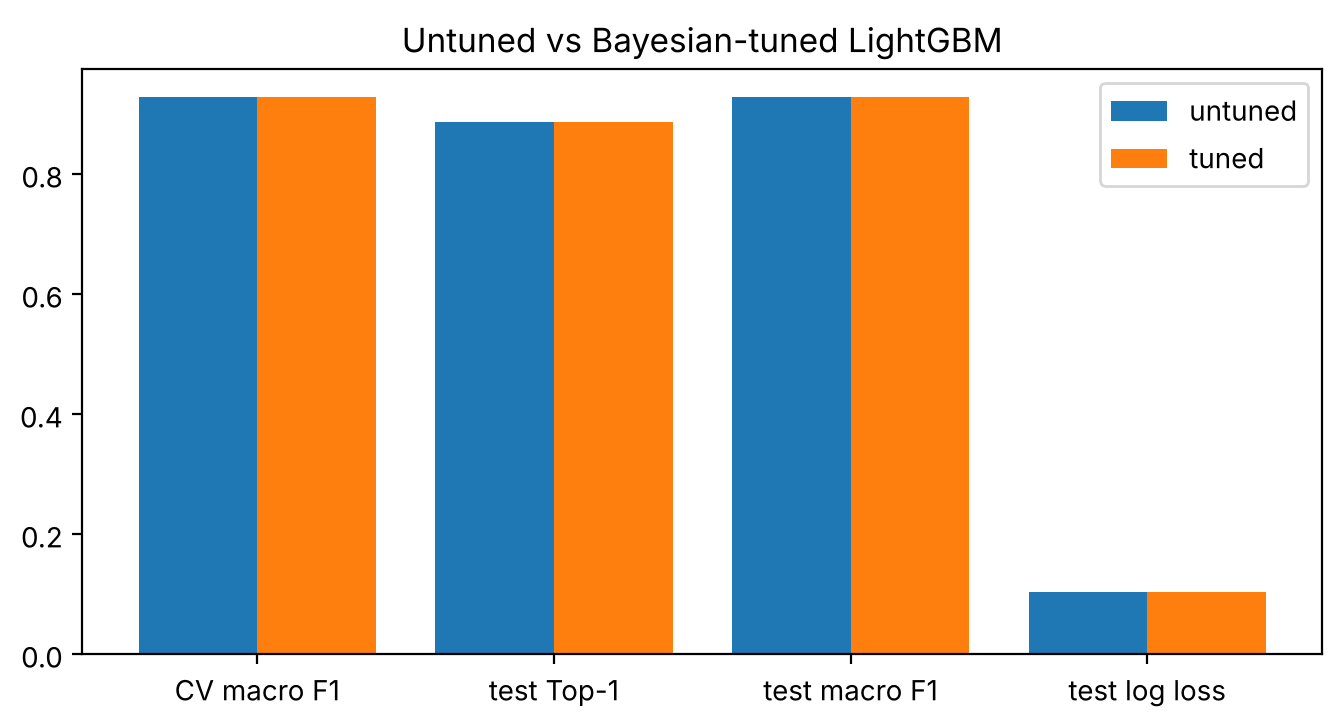

CV macro F1 change: +0.0001 (fold std about 0.0153)


In [8]:
ms = ["CV macro F1", "test Top-1", "test macro F1", "test log loss"]
x = np.arange(len(ms)); plt.figure(figsize=(8, 3.8))
plt.bar(x - .2, table.loc[ms, "untuned"], .4, label="untuned"); plt.bar(x + .2, table.loc[ms, "tuned"], .4, label="tuned")
plt.xticks(x, ms); plt.title("Untuned vs Bayesian-tuned LightGBM"); plt.legend(); nb.show()
d = table.loc["CV macro F1", "tuned"] - table.loc["CV macro F1", "untuned"]
print(f"CV macro F1 change: {d:+.4f} (fold std about {table.loc['CV std', 'untuned']:.4f})")

In [9]:
import joblib
joblib.dump(res["tuned"][3], "results/02_model_training/notebook_runs/lightgbm_tuned_notebook.joblib")
print("tuned model saved to results/02_model_training/notebook_runs/ (the deployed model stays models/final.joblib)")

tuned model saved to results/notebooks/ (the deployed model stays artifacts/models/final.joblib)
